# Tarea 27 · Evaluación de la clasificación

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/julianschmidt1/tpi-analisis-de-datos/blob/main/notebooks/trabajo/27_evaluacion_clasificacion.ipynb)

**TPI · Introducción al Análisis de Datos · UTN FRA · División 343**  
**Integrantes:** Matías, Julián y Emmanuel.

Evaluamos la Regresión Logística de la tarea 26 sobre clientes reservados para prueba. Calculamos exactitud, matriz de confusión y una línea base mayoritaria, e interpretamos los errores para una campaña de retención.

**Entrada:** los cuatro CSV de la tarea 23 en `data/processed/`. **Salida:** `reports/figures/27_matrices_confusion.png`. No se modifican las particiones.

## Cómo ejecutarlo

- **Local:** instalar `requirements.txt`, abrir este notebook dentro del repositorio y ejecutar todas las celdas en orden.
- **Colab:** abrir el botón y ejecutar todo; los CSV integrados se leen desde `main` de GitHub. La figura queda en el panel Archivos, en `reports/figures/`.


## 1. Carga y comprobación de las particiones

Conservamos `fila_origen` como índice y comprobamos alineación, separación de clientes y columnas. Las matrices ya están transformadas: no se vuelven a ajustar codificadores ni escaladores.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

try:
    import google.colab
except ImportError:
    EN_COLAB = False
else:
    EN_COLAB = True

actual = Path.cwd().resolve()
RAIZ = actual if EN_COLAB else next(
    (p for p in (actual, *actual.parents) if (p / 'data/processed/X_train.csv').is_file()), None
)
if RAIZ is None:
    raise FileNotFoundError('Abrí Jupyter dentro del repositorio con los CSV de la tarea 23.')

def leer(nombre):
    ruta = f'data/processed/{nombre}.csv'
    fuente = (f'https://raw.githubusercontent.com/julianschmidt1/tpi-analisis-de-datos/main/{ruta}'
              if EN_COLAB else RAIZ / ruta)
    return pd.read_csv(fuente, index_col='fila_origen')

X_train, X_test = leer('X_train'), leer('X_test')
y_train, y_test = leer('y_train')['Churn'], leer('y_test')['Churn']
for X, y in [(X_train, y_train), (X_test, y_test)]:
    assert X.index.is_unique and y.index.is_unique
    assert X.index.equals(y.index), 'Clientes y etiquetas desalineados.'
    assert np.isfinite(X.to_numpy(dtype=float)).all()
    assert set(y.unique()) == {0, 1}
assert X_train.index.intersection(X_test.index).empty
assert X_train.columns.equals(X_test.columns)
assert 'fila_origen' not in X_train.columns
print(f'Train: {len(X_train)} clientes; test: {len(X_test)}; predictores: {X_train.shape[1]}.')


Train: 5634 clientes; test: 1409; predictores: 46.


## 2. Modelo y línea base

La tarea 26 no serializa el modelo: reproducimos su ajuste con los mismos parámetros y solo train. `DummyClassifier(strategy='most_frequent')` aprende la clase mayoritaria **de train**, sin consultar test. Ambos predicen los mismos clientes de prueba. Mantenemos la regla de decisión de `predict` (umbral de probabilidad cercano a 0,5); no elegimos parámetros ni umbrales a partir de test.

In [2]:
modelo = LogisticRegression(max_iter=1000, random_state=42)
modelo.fit(X_train, y_train)
assert (modelo.n_iter_ < modelo.max_iter).all(), 'Revisar convergencia.'
base = DummyClassifier(strategy='most_frequent', random_state=42)
base.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
y_base = base.predict(X_test)
assert np.all(y_base == y_train.mode().iloc[0])

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
matriz_base = confusion_matrix(y_test, y_base, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
acc = accuracy_score(y_test, y_pred)
acc_base = accuracy_score(y_test, y_base)
resultados = pd.DataFrame([
    ['Regresión Logística', acc, tn, fp, fn, tp],
    ['Siempre clase mayoritaria', acc_base, *matriz_base.ravel()],
], columns=['Modelo', 'Accuracy test', 'VN', 'FP', 'FN', 'VP']).set_index('Modelo')
display(resultados)
print(f'Mejora de exactitud: {(acc - acc_base) * 100:.2f} puntos porcentuales.')
print(f'Aciertos adicionales: {int((y_pred == y_test).sum() - (y_base == y_test).sum())}.')
assert matriz.sum() == len(y_test)
assert np.isclose(acc, (tn + tp) / len(y_test))


,Accuracy test,VN,FP,FN,VP
Modelo,,,,,
Regresión Logística,0.805536,926,109,165,209
Siempre clase mayoritaria,0.734564,1035,0,374,0


Mejora de exactitud: 7.10 puntos porcentuales.
Aciertos adicionales: 100.


**Lectura de la tabla:** accuracy es la proporción total de aciertos. Como predominan las permanencias, siempre predecir permanencia puede lograr una cifra elevada sin detectar ninguna baja. La comparación utiliza test para ambos modelos y debe leerse junto con los tipos de error de las siguientes secciones.

## 3. Matrices de confusión

Las filas representan la realidad y las columnas la predicción: 0 = permanece, 1 = baja. Graficamos conteos con la misma escala de color para poder comparar el modelo con la línea base. Aplicamos el estilo común de la tarea 16 y exportamos a 300 dpi.

In [3]:
TAMANO_FIGURA = (9, 5)
DPI_EXPORTACION = 300
PALETA_CATEGORICA = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
COLORES_CHURN = {'No': '#0072B2', 'Yes': '#D55E00'}
MAPA_CORRELACION = 'vlag'
CARPETA_FIGURAS = RAIZ / 'reports' / 'figures'

def aplicar_estilo():
    """Aplica el estilo común del TPI a las figuras que se creen después."""
    sns.set_theme(
        style='whitegrid',
        context='notebook',
        font='DejaVu Sans',
        palette=PALETA_CATEGORICA,
        rc={
            'figure.figsize': TAMANO_FIGURA,
            'figure.dpi': 110,
            'figure.facecolor': 'white',
            'axes.facecolor': 'white',
            'axes.titlesize': 14,
            'axes.titleweight': 'bold',
            'axes.labelsize': 12,
            'xtick.labelsize': 11,
            'ytick.labelsize': 11,
            'legend.fontsize': 11,
            'axes.spines.top': False,
            'axes.spines.right': False,
            'grid.alpha': 0.25,
            'savefig.dpi': DPI_EXPORTACION,
            'savefig.facecolor': 'white',
        },
    )

def guardar_figura(fig, nombre):
    """Guarda fig en reports/figures/<nombre>.png a 300 dpi y devuelve Path.

    Usar un nombre sin ruta ni extensión, como '17_histograma_tenure'.
    Un nombre existente se sobrescribe para permitir regenerar el gráfico.
    Guardar antes de plt.show() y cerrar luego con plt.close(fig).
    """
    if not nombre or Path(nombre).name != nombre or Path(nombre).suffix:
        raise ValueError('Usá un nombre sin ruta ni extensión.')
    CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = CARPETA_FIGURAS / f'{nombre}.png'
    fig.savefig(ruta, dpi=DPI_EXPORTACION, bbox_inches='tight', facecolor='white')
    return ruta

aplicar_estilo()
print('Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.')


Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.


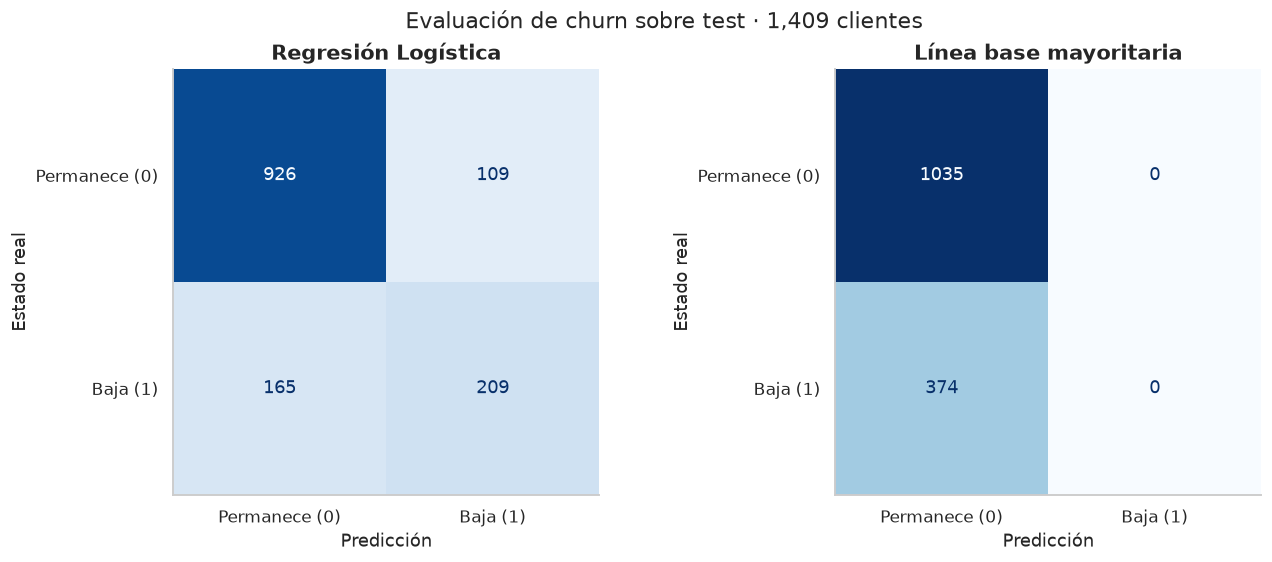

Figura: reports/figures/27_matrices_confusion.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, valores, titulo in zip(axes, [matriz, matriz_base],
                              ['Regresión Logística', 'Línea base mayoritaria']):
    disp = ConfusionMatrixDisplay(valores, display_labels=['Permanece (0)', 'Baja (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d',
              im_kw={'vmin': 0, 'vmax': max(matriz.max(), matriz_base.max())})
    ax.set_title(titulo)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Estado real')
    ax.grid(False)
fig.suptitle(f'Evaluación de churn sobre test · {len(y_test):,} clientes')
ruta_figura = guardar_figura(fig, '27_matrices_confusion')
plt.show()
plt.close(fig)
print(f'Figura: {ruta_figura.relative_to(RAIZ).as_posix()}')


## 4. Errores y decisiones de negocio

Un **falso negativo** es un cliente que se va pero al que el modelo clasifica como permanencia: puede quedar fuera de una campaña de retención. Un **falso positivo** es un cliente que permanece pero recibe una alerta: puede consumir presupuesto de contacto o incentivos innecesarios. Calculamos también recall y precisión de la clase baja para describir estos errores; no reemplazan la exactitud solicitada.

In [5]:
recall = tp / (tp + fn)
precision = tp / (tp + fp) if tp + fp else 0.0
print(f'Verdaderos negativos: {tn}; falsos positivos: {fp}.')
print(f'Falsos negativos: {fn}; verdaderos positivos: {tp}.')
print(f'Bajas detectadas: {tp} de {tp + fn} ({recall:.1%}).')
print(f'Bajas omitidas: {fn} de {tp + fn} ({1 - recall:.1%}).')
print(f'Alertas que corresponden a bajas: {tp} de {tp + fp} ({precision:.1%}).')


Verdaderos negativos: 926; falsos positivos: 109.
Falsos negativos: 165; verdaderos positivos: 209.
Bajas detectadas: 209 de 374 (55.9%).
Bajas omitidas: 165 de 374 (44.1%).
Alertas que corresponden a bajas: 209 de 318 (65.7%).


### Interpretación y cierre

La Regresión Logística acierta **1.135 de 1.409 clientes (80,55 %)**, frente a **1.035 (73,46 %)** de la línea base: mejora **7,10 puntos porcentuales**, equivalentes a 100 aciertos adicionales. La línea base predice siempre permanencia y omite las 374 bajas.

La matriz del modelo muestra **926 verdaderos negativos, 109 falsos positivos, 165 falsos negativos y 209 verdaderos positivos**. Detecta el **55,9 %** de las bajas y omite el **44,1 %** restante. De las 318 alertas, **65,7 %** corresponden a bajas reales. Por eso, una exactitud de 80,55 % no significa que se detecte ese porcentaje de clientes que se van.

- **165 falsos negativos:** clientes que abandonan sin ser señalados; representan oportunidades perdidas de contacto preventivo.
- **109 falsos positivos:** clientes que permanecen pero serían contactados; implican esfuerzo comercial y posibles descuentos innecesarios.

No asignamos costos monetarios porque el dataset no incluye el costo de contactar, el incentivo ni el valor perdido por abandono. Tampoco permite afirmar que una campaña hubiera evitado las bajas: eso requiere medir su efecto. Si perder un cliente cuesta más que contactarlo, convendría estudiar mayor sensibilidad, evaluando umbrales mediante validación dentro de train y considerando el presupuesto. El test ya utilizado se reserva como resultado de esta evaluación; no se usa para ajustar el modelo.

Resumen: exactitud y línea base calculadas sobre test, matrices graficadas y errores interpretados. El resultado describe esta partición y no garantiza el mismo rendimiento en clientes futuros.